### model training with global prior.
#### Note: 
1. train global surface water mapping model.    
2. using global prior for local patch-based model training. 



In [1]:
import time
import torch
import random
import numpy as np 
import pandas as pd 
import torch.nn as nn
from glob import glob
from pyrsimg import imsShow
from processing import config
import matplotlib.pyplot as plt
import torch.nn.functional as F
from utils.utils import read_imgs
from torchvision.transforms import v2
from dataloader.data_aug import GaussianNoise
from dataloader.data_loader import SceneArraySet, PatchPathSet
from torchmetrics.classification import MulticlassJaccardIndex, BinaryAccuracy
from model import unet_backbone_timm
from model import unet, unet_att, deeplabv3plus_mobilev2, swin_unet, watnet
from model.mamba_seg.mamba_seg import MambaSeg  
from model.mamba_seg.mamba_seg_global import MambaSeg_global   


/home/xin/miniconda3/envs/watnet/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
# patch_size = 1024           ## patch size setting
patch_resize = None        ## patch resize setting
learning_rate = 1e-4     
batch_size = 1
device = torch.device('cuda:0')   


In [3]:
### traset
paths_tra_scene = config.paths_tra_scene
paths_tra_truth = config.paths_tra_truth
print(f'train_scenes: {len(paths_tra_scene)}')
## valset
paths_val_scene = config.paths_val_scene
paths_val_truth = config.paths_val_truth
print(f'val_scenes: {len(paths_val_scene)}')



train_scenes: 172
val_scenes: 43


### dataset loading

In [9]:
## tradata
tra_scenes_arr, tra_truths_arr = read_imgs(paths_tra_scene, paths_tra_truth) 
tra_struth_ls =  list(zip(tra_scenes_arr, tra_truths_arr))
tra_struth_ls = [np.concatenate([scene, truth], axis=-1) 
                                        for scene, truth in tra_struth_ls] 
## valdata
val_scenes_arr, val_truths_arr = read_imgs(paths_val_scene, paths_val_truth) 
val_struth_ls =  list(zip(val_scenes_arr, val_truths_arr))
val_struth_ls = [np.concatenate([scene, truth], axis=-1) 
                                        for scene, truth in val_struth_ls] 


In [ ]:
# global prior inference model training  
transforms_tra = v2.Compose([
      v2.RandomApply([v2.RandomRotation(degrees=15)], p=0.3),
      v2.RandomHorizontalFlip(p=0.3),
      v2.RandomVerticalFlip(p=0.3),
      GaussianNoise(mean=0, sigma_max=0.05, p=0.3),   ## better than v2.GaussianNoise()  
       ])


In [51]:
## local patch-based model training
# transforms_tra = v2.Compose([
#       v2.RandomCrop(size=(patch_size, patch_size), 
#               padding = 50, 
#               pad_if_needed=True,   # pad the image if it's smaller than the desired size
#               fill=0,
#               ),
#       v2.RandomApply([v2.RandomRotation(degrees=15)], p=0.3),
#       v2.RandomHorizontalFlip(p=0.3),
#       v2.RandomVerticalFlip(p=0.3),
#       GaussianNoise(mean=0, sigma_max=0.05, p=0.3),   ## better than v2.GaussianNoise()  
#        ])



In [11]:
tra_dset = SceneArraySet(scene_truth_list = tra_struth_ls, transforms = transforms_tra)
val_dset = SceneArraySet(scene_truth_list = val_struth_ls, transforms = None)
### Create DataLoader
tra_loader = torch.utils.data.DataLoader(tra_dset, batch_size=batch_size,   
                                                      shuffle=True, num_workers=4)     
val_loader = torch.utils.data.DataLoader(val_dset, batch_size=batch_size, num_workers=5)     


array([<Axes: title={'center': 'patch'}>,
       <Axes: title={'center': 'truth'}>], dtype=object)

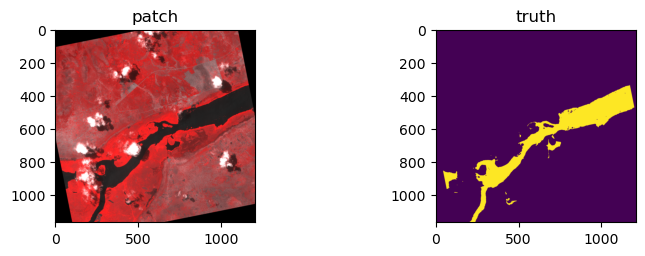

In [12]:
## show train/validation data.    
i = random.randint(0, len(tra_dset)-1)
patch, truth = tra_dset[i]
imsShow([patch.numpy().transpose(1,2,0), truth.numpy()[0]],
            clip_list = (2,0),
            img_name_list=['patch', 'truth'], 
            color_bands_list=([3,2,2], 0),                    
            figsize=(9, 2.5))


#### Model training

In [13]:
### check model
# model = unet(num_bands=6)
# model = watnet(num_bands=6)
## model with pretrained 
# # for cnn backbone
# model = unet_backbone_timm(num_bands=6, 
#                          backbone_name='efficientnet_b0', 
#                         # backbone_name='mobilenetv3_large_100',
#                         # backbone_name='resnet50',
#                           # backbone_name='vit_large_patch16_dinov3.sat493m',
#                           # backbone_name='vit_small_plus_patch16_dinov3.lvd1689m',
#                           pretrained=True,
#                           ).to('cuda')

## for swin transformer backbone（img_size setting is required.）      
# model = unet_backbone_timm(num_bands=6, 
#                          img_size = 512, 
#                          backbone_name='swinv2_base_window8_256',
#                          pretrained=True).to('cuda')
### mamba backbone  
model = MambaSeg_global(in_chans=6, 
                    num_classes=1, 
                    decoder_channels=32,  
                    dims=96,   
                    depths=(2, 2, 8, 2),  
                    # backend='torch',   
                    backend='oflex',   
                    pretrained = True   
                    ).to('cuda')  
model_name = 'unet_mamba_pretrain_global'  ## model name for saving  


Loaded model/weights/vssm1_tiny_0230s_ckpt_epoch_264.pth; newly initialized output norms: ['outnorm0.weight', 'outnorm0.bias', 'outnorm1.weight', 'outnorm1.bias', 'outnorm2.weight', 'outnorm2.bias', 'outnorm3.weight', 'outnorm3.bias']


In [14]:
# input_tensor = torch.randn(2, 6, 512, 512)
input_tensor = torch.randn(2, 6, 612, 812, device='cuda')
output,_ = model(input_tensor)
print(output.shape)


torch.Size([2, 1, 612, 812])


In [15]:
### create loss and optimizer
bce_loss = nn.BCEWithLogitsLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)  
# lr_scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, \
#                                       mode='max', 
#                                       factor=0.5, 
#                                       patience=10,
#                                       min_lr=1e-5)


In [16]:
sam_index = random.randrange(len(val_dset))
patch_val, truth_val = val_dset[sam_index]
def show_result(model, patch, truth):
    model.eval()
    device = next(model.parameters()).device
    patch, truth = patch.unsqueeze(0).to(device), truth.to(device)
    pred,_ = model(patch) 
    pred = F.sigmoid(pred)   ## convert to probability
    ## convert to numpy and plot
    patch = patch[0].to('cpu').detach().numpy().transpose(1,2,0)            
    pred = pred[0].to('cpu').detach().numpy()
    truth = truth.to('cpu').detach().numpy()
    imsShow([patch, pred, truth],   
            clip_list = (2,0,0),
            img_name_list=['patch', 'pred', 'truth'], 
            color_bands_list=([3,2,2], 0, 0),                    
            figsize=(9, 2.5))
    plt.tight_layout() 
    plt.show()   


In [17]:
'''------train loops------'''
def train_loops(model, loss_fn, 
                    optimizer, 
                    tra_loader, 
                    val_loader,  
                    epoches, 
                    device, 
                    lr_scheduler=None):
    loss_tra_loops, miou_tra_loops, oa_tra_loops = [], [], []
    loss_val_loops, miou_val_loops, oa_val_loops = [], [], []
    model = model.to(device)
    size_tra_loader = len(tra_loader)
    size_val_loader = len(val_loader)
    best_miou = 0.92
    epoches_i = []
    for epoch in range(epoches):
        start = time.time()
        loss_tra, loss_val = 0, 0
        '''-----train the model-----'''
        oa_tra = BinaryAccuracy().to(device)
        miou_tra = MulticlassJaccardIndex(num_classes=2, average="macro").to(device)
        model.train()   # training mode for dropout and batchnorm
        for x_batch, y_batch in tra_loader:
            x_batch, y_batch = x_batch.to(device), y_batch.to(device)
            optimizer.zero_grad()
            pred,_ = model(x_batch)
            loss = loss_fn(pred, y_batch)
            loss.backward()
            optimizer.step()
            pred = (F.sigmoid(pred) > 0.5).float()
            miou_tra.update(pred, y_batch.long())
            oa_tra.update(pred, y_batch.long())
            loss_tra += loss.item()
        miou_tra_global = miou_tra.compute()
        oa_tra_global = oa_tra.compute()
        loss_tra_global = loss_tra/size_tra_loader
        miou_tra.reset(); oa_tra.reset()

        '''----- validation the model: time consuming -----'''
        oa_val = BinaryAccuracy().to(device)
        miou_val = MulticlassJaccardIndex(num_classes=2, average="macro").to(device)
        model.eval()
        if epoch > 100 and (epoch+1) % 2 == 0: 
            for x_batch, y_batch in val_loader:
                x_batch, y_batch = x_batch.to(device), y_batch.to(device)
                with torch.no_grad():
                    pred,_ = model(x_batch)
                    loss = loss_fn(pred, y_batch)
                pred = (F.sigmoid(pred) > 0.5).long()
                miou_val.update(pred, y_batch.long())
                oa_val.update(pred, y_batch.long())
                loss_val += loss.item()
            miou_val_global = miou_val.compute()
            oa_val_global = oa_val.compute()
            loss_val_global = loss_val/size_val_loader
            miou_val.reset(); oa_val.reset()
            loss_tra_loops.append(loss_tra_global); miou_tra_loops.append(miou_tra_global.item()); oa_tra_loops.append(oa_tra_global.item())
            loss_val_loops.append(loss_val_global); miou_val_loops.append(miou_val_global.item()); oa_val_loops.append(oa_val_global.item())
            epoches_i.append(epoch)
            print(f'Ep{epoch}: tra-> Loss:{loss_tra_global:.3f},Oa:{oa_tra_global:.3f},Miou:{miou_tra_global:.3f}, '
                    f'val-> Loss:{loss_val_global:.4f},Oa:{oa_val_global:.4f}, Miou:{miou_val_global:.4f},time:{time.time()-start:.1f}s')
            ## save the best model
            if miou_val_global.item() > best_miou:
                best_miou = miou_val_global.item()       ## update best miou
                torch.save(model.state_dict(), f'model/trained/{model_name}_epoch_{epoch}_0{str(round(best_miou*10000))}.pth')
        else: 
            print(f'Ep{epoch}: tra-> Loss:{loss_tra_global:.3f},Oa:{oa_tra_global:.3f},Miou:{miou_tra_global:.3f}, \
                                time:{time.time()-start:.1f}s')
        if lr_scheduler: lr_scheduler.step(miou_tra_global)    ## if use lr_scheduler like ReduceLROnPlateau
        if (epoch+1)%50 == 0:
            sam_index = random.randrange(len(val_dset))
            patch_val, truth_val = val_dset[sam_index] 
            show_result(model=model, patch=patch_val, truth=truth_val)   
    metrics = {'epoch':epoches_i, 'tra_loss':loss_tra_loops, 'tra_oa': oa_tra_loops, 'tra_miou': miou_tra_loops,
                'val_loss': loss_val_loops, 'val_oa': oa_val_loops, 'val_miou': miou_val_loops}
    return metrics  


In [ ]:
if __name__ == '__main__':
    metrics = train_loops(model=model,  
                    epoches=500,   
                    loss_fn=bce_loss,   
                    optimizer=optimizer,  
                    tra_loader=tra_loader,   
                    val_loader=val_loader,   
                    # lr_scheduler=lr_scheduler,   
                    device=device)   


In [ ]:
# torch.save(model.state_dict(), f'model/trained/{model_name}_.pth')
# ## metrics saving
# path_metrics = f'model/trained/{model_name}_training_metrics.csv'   
# metrics_df = pd.DataFrame(metrics)
# metrics_df.to_csv(path_metrics, index=False, sep=',')  

